# Setup of the libraries

Notes on the napari configuration. It took me a couple of hours to configure the setup of the napari in my local environment. I use python 3.10.22 fo my project, and I needed version of napari that would be compatible. I used [official documentation](https://napari.org/stable/getting_started/installation.html) to install library in conda environment.

Although it was advised to create new environment by the developers, I wanted to use it in my exosting environment called `diff`

In my terminal I ran
```
conda activate diff
pip install "napari[all]"

```

Common pitfall: if kernel crashes at `viewer.add_image()`, it could be due to the two copies of Qt stored in conda (Qt is a fancy user interface for the python shell, according to reddit). I was able to resolve it just by removing the pyqt version that conflicted with pyqt5.

`conda remove -n diff pyqt6 pyqt6-sip qt6-main --force -y`                                                                                                                          







In [2]:
%gui qt
import napari
import numpy as np
import dbdicom as db
import dcmri as dc
import mdreg
import matplotlib.pyplot as plt
import vreg


# Volume processing

In [3]:
DATAPATH = r"path\to\ibeat_dce\stage_3_data_harmonization\Patients\Sheffield"
series = db.series(DATAPATH)[0]
volume = db.volume(series, 'TriggerTime')

Reading volume..: 100%|██████████| 7168/7168 [00:35<00:00, 202.97it/s]


In [41]:
# define the output for the motion corrected series
OUT_PATH = series[:-1] 
print(OUT_PATH)

In [5]:
# convert time from miliseconds to seconds
time = volume.coords[0]/1000
time = time - time[0]
display(time)

array([0.0, 1.898, 3.797, 5.696, 7.594, 9.493, 11.392, 13.29, 15.189,
       17.088, 18.986, 20.885, 22.784, 24.682, 26.581, 28.48, 30.379,
       32.277, 34.176, 36.075, 37.973, 39.872, 41.771, 43.669, 45.568,
       47.467, 49.365, 51.264, 53.163, 55.061, 56.96, 58.859, 60.758,
       62.656, 64.555, 66.454, 68.352, 70.251, 72.15, 74.048, 75.947,
       77.846, 79.744, 81.643, 83.542, 85.44, 87.339, 89.238, 91.137,
       93.035, 94.934, 96.833, 98.731, 100.63, 102.529, 104.427, 106.326,
       108.225, 110.123, 112.022, 113.921, 115.819, 117.718, 119.617,
       121.516, 123.414, 125.313, 127.212, 129.11, 131.009, 132.908,
       134.806, 136.705, 138.604, 140.502, 142.401, 144.3, 146.198,
       148.097, 149.996, 151.895, 153.793, 155.692, 157.591, 159.489,
       161.388, 163.287, 165.185, 167.084, 168.983, 170.881, 172.78,
       174.679, 176.577, 178.476, 180.375, 182.274, 184.172, 186.071,
       187.97, 189.868, 191.767, 193.666, 195.564, 197.463, 199.362,
       201.26, 203.1

In [6]:
# get signal
signal = volume.values

# get type of the vriable signal (should be numpy ndarray)
display(type(signal))

numpy.ndarray

In [7]:
# get shape of the signal
signal.shape

(256, 256, 28, 256)

Volume shape is (256, 256, 28, 256). From this:

| axis | size | meaning |
| --- | ---- | -------- |
| 0 | 256 | x |
| 1 | 256 | y |
| 2 | 28 | slices |
| 3 | 256 | time |

Note: time could be 144 for the images with shorter acquisition time

Napari by default takes last two axis variables and uses them as x, y. Hence the signal should be transposed to be used in the viewer

It is important to note that just as testing of different algorithms, only first 40 time frames were chosen for the motion correction algorithm. This is done to reduce the computational load and enable tests on the local computer

In [9]:
n = 40
# trim not only signal but the whole volume itself (includes geometry, time, coordinates and dimension)
volume_trimmed = vreg.volume(
    volume.values[..., :n],                     # trimmed signal (x, y, z, n)
    volume.affine,                              # geometry is unchanged
    coords=[np.asarray(volume.coords[0])[:n]],  # trimmed time coordinates
    dims=volume.dims,                           # dimension is kept as 'TriggerTime'
)

# get signal and time trimmed
signal_trimmed = volume_trimmed.values
time_trimmed = volume_trimmed.coords[0]/1000
time_trimmed = time_trimmed - time_trimmed[0]

# check shape of the trimmed signal and number of time points 
display(signal_trimmed.shape, len(time_trimmed))  

(256, 256, 28, 40)

40

# Exploration of data with napari
### Minimal code needed to start playing with napari and explore the signal before adding any masks

```
viewer = napari.Viewer()
viewer.add_image(signal.T)
napari.run()
```

Note: Napari uses last 2 axis as image plane --> signal needs to be transposed from (x, y, n_slices, time) to (time, n_slices, y, x)


In [33]:
viewer = napari.Viewer()
viewer.add_image(signal.T)
napari.run()

# Setting up the functions for image processing

The code below is mostly stolen (with pride) from the following miblab repo: [ntbk-dcmri](https://github.com/openmiblab/ntbk-dcmri/blob/main/src/case_studies/lung_dce.py)

In [10]:
# Note this function works in the notebook but needs to be adjusted when written in the python script 

def draw_mask(signal: np.ndarray, mask=None, name='ROI', contrast_limits=None) -> np.ndarray:
    # Ensure that the input signal is numpy array. Transpose signal to make input suitable for the napari viewer
    signal = np.asarray(signal).T

    # Initilise the mask
    if mask is None:
        # create array full of zeros (dtype=np.uint8 sets the data type of the mask as integer instead of float)
        mask = np.zeros_like(signal, dtype=np.uint8) # NOTE: this mask should noy be transposed since signal is already transformed
    else:
        mask = np.asarray(mask).T

    # Start the napari viewer and add the signal without any masks
    viewer = napari.Viewer()
    viewer.add_image(signal, name='Data', blending='additive', contrast_limits=contrast_limits)

    # Add mask and labels (mask should be drawn by hand when the viewer opens)
    labels_layer = viewer.add_labels(mask, name=name)
    viewer.layers.selection.active = labels_layer
    labels_layer.mode = 'paint'
    labels_layer.brush_size = 6 

    # Block execution strictly until THIS viewer window is closed
    viewer.show(block=True)

    # After closing napari, extract the mask
    mask = (labels_layer.data > 0).astype(np.uint16)

    # return transposed mask .T moves dimensions back to (x, y, n_slices, time)
    return mask.T


In [10]:
type(time)

numpy.ndarray

In [11]:
def dce_motion_correction(volume: vreg.vol.Volume3D, time: np.ndarray, 
                          aif_signal:np.ndarray, out_path: list, series: list,
                          model_fit_optn="fit_pca", coreg_optn="fit_skimage") -> np.ndarray:
    # Model fitting options
    fit_options = {
        "fit_pca": {
            'func': mdreg.fit_pca,
            'n_components': 8,
        },
        "fit_2cm": {
            'func': mdreg.fit_2cm_lin,
            'time': time,
            'aif': aif_signal,
            'baseline': 1,
            'input_corr': True,
        },
        "fit_deconv":{
            'func': mdreg.fit_deconvolution,
            'aif': aif_signal,
            'n0': 1,
            'tol': 0.2,
        },
    }

    # Coregistration options
    coreg_options = {
        "fit_ants":{
            'package': 'ants',
            'type_of_transform': 'SyNOnly',
            'parallel': True,
            'progress_bar': False,  
        },
        "fit_skimage":{
            'package': 'skimage',
            'attachment': 10,
            'parallel': True,
            'progress_bar': False,  
        },
    }
    
    # Perform motion correction
    coreg, fit, _, _ = mdreg.fit(
        volume.values, fit_image=fit_options[model_fit_optn], fit_coreg=coreg_options[coreg_optn], 
        maxit = 2, verbose = 2,
    )

    # Save results to DICOM
    vol_coreg = vreg.volume(coreg, volume.affine, coords=volume.coords, dims=volume.dims)
    db.delete(out_path, not_exists_ok=True)
    db.write_volume(vol_coreg, out_path, ref=series)
    return coreg

# Code to draw and create aorta mask 

Note: the code uses trimmed signal with only 40 time frames just to speed up the calculation process

In [12]:
# drawing aorta mask
ref = signal_trimmed.max(axis=-1)
aorta_mask = draw_mask(ref, name='aorta')   # paint in the window, then close it

# check if the mask is not empty (output should be > 0)
print(aorta_mask.sum())                  

3754


In [13]:
mask = aorta_mask > 0
print(mask.shape, aorta_mask.shape, mask.sum()) 

(256, 256, 28) (256, 256, 28) 3754


In [14]:
aif_trimmed = signal_trimmed[mask, :].mean(axis=0)

In [15]:
print(aif_trimmed.shape)

(40,)


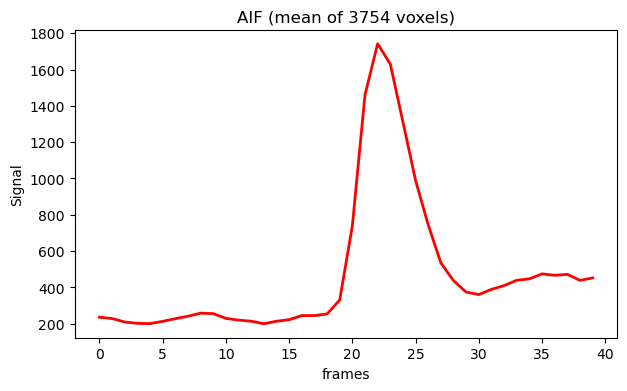

In [29]:
n_frames = signal_trimmed.shape[-1]  
frames = np.arange(n_frames)

plt.figure(figsize=(7, 4))
plt.plot(frames, aif_trimmed, color='red', lw=2)
plt.xlabel('frames')
plt.ylabel('Signal')
plt.title(f'AIF (mean of {mask.sum()} voxels)')
plt.show()

# Motion correction with skimage


In [17]:
# model_fit_optn="fit_pca", coreg_optn="fit_skimage"
dce_motion_correction(volume=volume_trimmed, 
                      aif_signal=aif_trimmed,
                      time=time_trimmed, 
                      out_path=OUT_PATH + ['motion_corr_pca_skimage'],
                      series=series,  
                      model_fit_optn="fit_pca", 
                      coreg_optn="fit_skimage")

Initializing..
Iteration 1: fitting signal model
Iteration 1: fitting deformation fields
Calculation time for iteration 1: 11.62929707368215 min
Iteration 2: fitting signal model
Iteration 2: fitting deformation fields
Calculation time for iteration 2: 11.251554624239605 min
Total calculation time: 22.884006893634798 min


Writing volume..: 100%|██████████| 40/40 [00:42<00:00,  1.06s/it]


array([[[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        ...,

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
    

In [18]:
# model_fit_optn="fit_2cm", coreg_optn="fit_skimage"
dce_motion_correction(volume=volume_trimmed, 
                      aif_signal=aif_trimmed,
                      time=time_trimmed, 
                      out_path=OUT_PATH + ['motion_corr_2cm_skimage'],
                      series=series,  
                      model_fit_optn="fit_2cm", 
                      coreg_optn="fit_skimage")

Initializing..
Iteration 1: fitting signal model


Fitting 2-comp model: 100%|██████████| 1835008/1835008 [15:06<00:00, 2023.74it/s]


Iteration 1: fitting deformation fields
Calculation time for iteration 1: 27.47461367448171 min
Iteration 2: fitting signal model


Fitting 2-comp model: 100%|██████████| 1835008/1835008 [13:53<00:00, 2202.57it/s]


Iteration 2: fitting deformation fields
Calculation time for iteration 2: 25.366159085432688 min
Total calculation time: 52.84393978913625 min


Writing volume..: 100%|██████████| 40/40 [00:42<00:00,  1.06s/it]


array([[[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        ...,

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
    

In [20]:
# model_fit_optn="fit_deconv", coreg_optn="fit_skimage"
dce_motion_correction(volume=volume_trimmed, 
                      aif_signal=aif_trimmed,
                      time=time_trimmed, 
                      out_path=OUT_PATH + ['motion_corr_deconv_skimage'],
                      series=series,  
                      model_fit_optn="fit_deconv", 
                      coreg_optn="fit_skimage")

Initializing..
Iteration 1: fitting signal model
Iteration 1: fitting deformation fields
Calculation time for iteration 1: 12.514420557022095 min
Iteration 2: fitting signal model
Iteration 2: fitting deformation fields
Calculation time for iteration 2: 11.428870598475138 min
Total calculation time: 23.950126032034557 min


Writing volume..: 100%|██████████| 40/40 [00:36<00:00,  1.08it/s]


array([[[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        ...,

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
    

# Coregistration with ants (additional package is needed)

In [ ]:
# model_fit_optn="fit_pca", coreg_optn="fit_ants"
dce_motion_correction(volume=volume_trimmed, 
                      aif_signal=aif_trimmed,
                      time=time_trimmed, 
                      out_path=OUT_PATH + ['motion_corr_pca_ants'],
                      series=series,  
                      model_fit_optn="fit_pca", 
                      coreg_optn="fit_ants")

In [ ]:
# model_fit_optn="fit_2cm", coreg_optn="fit_ants"
dce_motion_correction(volume=volume_trimmed, 
                      aif_signal=aif_trimmed,
                      time=time_trimmed, 
                      out_path=OUT_PATH + ['motion_corr_2cm_ants'],
                      series=series,  
                      model_fit_optn="fit_2cm", 
                      coreg_optn="fit_ants")

In [ ]:
# model_fit_optn="fit_deconv", coreg_optn="fit_ants"
dce_motion_correction(volume=volume_trimmed, 
                      aif_signal=aif_trimmed,
                      time=time_trimmed, 
                      out_path=OUT_PATH + ['motion_corr_deconv_ants'],
                      series=series,  
                      model_fit_optn="fit_deconv", 
                      coreg_optn="fit_ants")

# Visualise the motion corrected series

In [22]:
vol_corr_pca_skimage = db.volume(OUT_PATH + ['motion_corr_pca_skimage'], 'TriggerTime')
vol_corr_2cm_skimage = db.volume(OUT_PATH + ['motion_corr_2cm_skimage'], 'TriggerTime')
vol_corr_deconv_skimage = db.volume(OUT_PATH + ['motion_corr_deconv_skimage'], 'TriggerTime')
# vol_corr_pca_ants = db.volume(OUT_PATH + ['motion_corr_pca_ants'], 'TriggerTime')
# vol_corr_2cm_ants = db.volume(OUT_PATH + ['motion_corr_2cm_ants'], 'TriggerTime')
# vol_corr_deconv_ants = db.volume(OUT_PATH + ['motion_corr_deconv_ants'], 'TriggerTime')

Reading volume..: 100%|██████████| 1120/1120 [00:20<00:00, 53.87it/s]


In [27]:
viewer = napari.Viewer()
viewer.add_image(vol_corr_pca_skimage.values.T, name='motion_corr_pca_skimage')
viewer.add_image(vol_corr_2cm_skimage.values.T, name='motion_corr_2cm_skimage')
viewer.add_image(vol_corr_deconv_skimage.values.T, name='motion_corr_deconv_skimage')
viewer.add_image(volume_trimmed.values.T, name='original image')
mask_layer = viewer.add_labels(aorta_mask.T.astype(np.uint8), name='aorta_mask', opacity=0.5)
# viewer.add_image(vol_corr_pca_ants.values.T, name='motion_corr_pca_ants')
# viewer.add_image(vol_corr_2cm_ants.values.T, name='motion_corr_2cm_ants')
# viewer.add_image(vol_corr_deconv_ants.values.T, name='motion_corr_deconv_ants')

In [39]:
viewer = napari.Viewer()
viewer.add_image(vol_corr_2cm_skimage.values.T, name='motion_corr_2cm_skimage')

<Image layer 'motion_corr_2cm_skimage' at 0x18b984f6200>

In [ ]:
# TODO substract two images
# TODO: look at the average of the frames for the TotalSegemntator 

In [32]:
# signal = signal.max(axis=-1)

In [36]:
pca_skimage_signal = vol_corr_pca_skimage.values

substract = np.subtract(signal_trimmed, pca_skimage_signal)


In [38]:
print(substract.sum())


37207014
